In [1]:
import os
import numpy as np
import pandas as pd
import warnings
import seaborn as sns
from math import sqrt
from itertools import cycle
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, ShuffleSplit, StratifiedShuffleSplit, GroupKFold, LeaveOneGroupOut, GroupShuffleSplit, TimeSeriesSplit
from sklearn.model_selection._split import _BaseKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module='multiprocessing')
%matplotlib inline

In [2]:
###df = pd.read_csv("/content/women_in_stem.csv")
df = pd.read_csv("/Users/devianted/Downloads/women_in_stem.csv")

In [3]:
df.head()

,Country,Year,Female Enrollment (%),Female Graduation Rate (%),STEM Fields,Gender Gap Index
0,China,2018,20.4,43.2,Engineering,0.52
1,China,2005,35.6,29.3,Mathematics,0.98
2,China,2005,53.7,32.4,Biology,0.60
3,Germany,2007,65.0,63.6,Mathematics,0.69
4,Canada,2010,54.4,28.8,Engineering,0.74


Подготовка данных


In [4]:
df = pd.get_dummies(df, columns=['STEM Fields'], prefix='Field')

print(df.head())

   Country  Year  Female Enrollment (%)  Female Graduation Rate (%)  \
0    China  2018                   20.4                        43.2   
1    China  2005                   35.6                        29.3   
2    China  2005                   53.7                        32.4   
3  Germany  2007                   65.0                        63.6   
4   Canada  2010                   54.4                        28.8   

   Gender Gap Index  Field_Biology  Field_Computer Science  Field_Engineering  \
0              0.52          False                   False               True   
1              0.98          False                   False              False   
2              0.60           True                   False              False   
3              0.69          False                   False              False   
4              0.74          False                   False               True   

   Field_Mathematics  
0              False  
1               True  
2              Fa

In [5]:
# Разобьём по годам и найдём пороговый год (до - будет train) по квантилю 80% уникальных лет
years_sorted = np.sort(df["Year"].unique())
cutoff_idx = int(len(years_sorted) * 0.8) if len(years_sorted) > 1 else 1
cutoff_year = years_sorted[min(cutoff_idx, len(years_sorted)-1)]

train_df = df[df["Year"] <= cutoff_year].copy()
test_df  = df[df["Year"] >  cutoff_year].copy()

pd.DataFrame({
    "part": ["train", "test", "пороговый год"],
    "value": [len(train_df), len(test_df), cutoff_year]
})

,part,value
0,train,409
1,test,91
2,пороговый год,2019


In [6]:
target_col = "Female Graduation Rate (%)"
feature_cols = ["Female Enrollment (%)", "Gender Gap Index", "Year", "Field_Biology", "Field_Computer Science", "Field_Engineering", "Field_Mathematics"]

X_train = train_df[feature_cols].copy()
Y_train = train_df[target_col].to_numpy()  # исправлено: заменено .ravel() на .to_numpy()
X_test = test_df[feature_cols].copy()

X_train = X_train.values
X_test = X_test.values

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")


X_train shape: (409, 7)
X_test shape: (91, 7)


In [7]:
clf = LinearRegression()
X = X_train
y = Y_train

Валидация 1

Random Permutation(Cross Validation)

Результаты кросс валидации:
{'fit_time': array([0.00219607, 0.00174308, 0.00203204, 0.00199699, 0.00177097]), 'score_time': array([0.00095606, 0.00088191, 0.00092196, 0.00091124, 0.00094509]), 'test_r2': array([-0.07477651,  0.0212592 , -0.05360853, -0.0197584 ,  0.0184572 ]), 'test_mae': array([-15.31606997, -13.40800482, -14.77922756, -13.16434345,
       -13.60450361]), 'test_rmse': array([-17.13957188, -15.45001481, -16.65276137, -15.36659067,
       -15.58456752])}
Результаты ShuffleSplit:
R²   : -0.0217 ± 0.0382
MAE  : 14.0544 ± 0.8402
RMSE : 16.0387 ± 0.7202


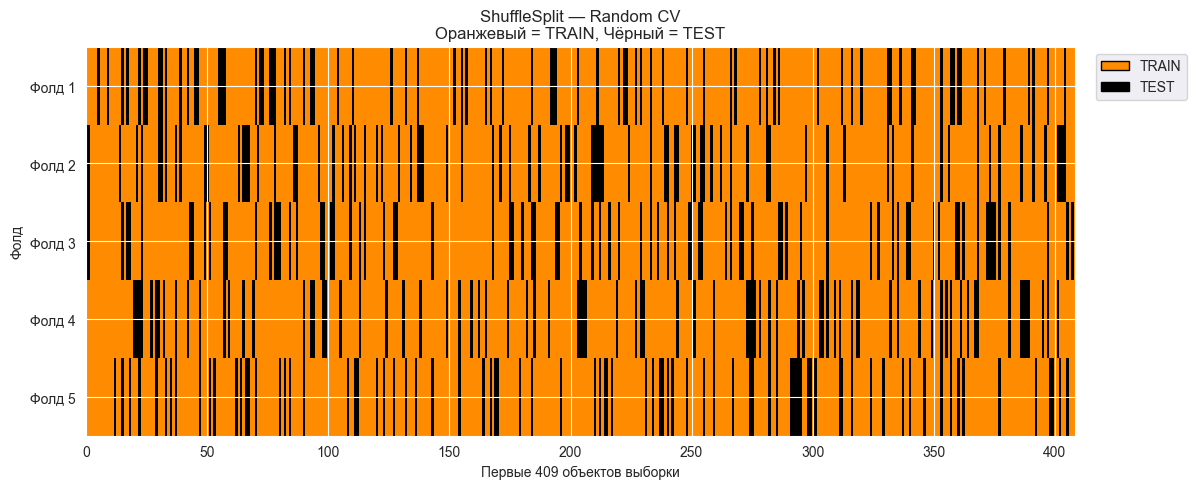

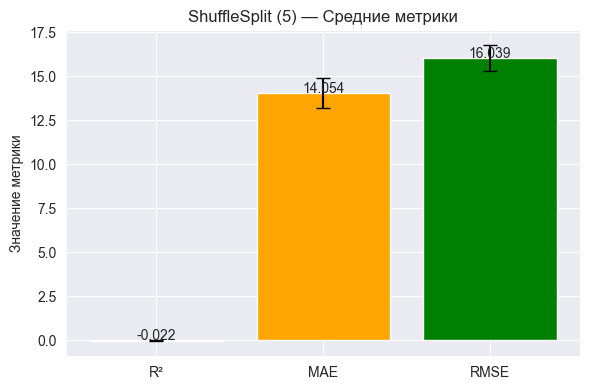


Сводная таблица метрик:


,Validation Type,R2,MAE,RMSE
0,ShuffleSplit (5 splits),-0.021685,14.05443,16.038701


In [8]:
NFOLDS = 5
SEED = 42
splitter = ShuffleSplit(n_splits=NFOLDS, train_size=0.7, test_size=0.2, random_state=SEED)

scoring = { #обозначаем метрики
    'r2': make_scorer(r2_score),
    'mae': make_scorer(mean_absolute_error, greater_is_better=False),
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred) ** 0.5, greater_is_better=False)
}

cv_res = cross_validate( # делаем кросс валидацию
    clf, X, y,
    cv=splitter,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)
print("Результаты кросс валидации:")
print(cv_res)

# высчитываем метрики средние
res = {
    'cv': 'ShuffleSplit (5 splits)',
    'r2_mean': np.mean(cv_res['test_r2']),
    'r2_std': np.std(cv_res['test_r2']),
    'mae_mean': -np.mean(cv_res['test_mae']),
    'mae_std': np.std(cv_res['test_mae']),
    'rmse_mean': -np.mean(cv_res['test_rmse']),
    'rmse_std': np.std(cv_res['test_rmse'])
}

print("Результаты ShuffleSplit:")
print(f"R²   : {res['r2_mean']:.4f} ± {res['r2_std']:.4f}")
print(f"MAE  : {res['mae_mean']:.4f} ± {res['mae_std']:.4f}")
print(f"RMSE : {res['rmse_mean']:.4f} ± {res['rmse_std']:.4f}")

# Обновляем таблицу метрик
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'R2', 'MAE', 'RMSE'])

new_row = pd.DataFrame([{
    'Validation Type': res['cv'],
    'R2': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}])

if 'stats' not in globals() or stats.empty:
    stats = new_row
else:
    stats = pd.concat([stats, new_row], ignore_index=True)

# Визуалиируем разбиения (train/test)
splits = list(splitter.split(X, y))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0  # train
    mat[i, test_idx] = 1   # test

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Первые {x_display} объектов выборки")
ax.set_ylabel('Фолд')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Фолд {i+1}' for i in range(n_folds)])
ax.set_title('ShuffleSplit — Random CV\nОранжевый = TRAIN, Чёрный = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# рисуем графики метрик
metrics_plot = {
    'R²': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(),
              color=['skyblue','orange','green'],
              yerr=[res['r2_std'], res['mae_std'], res['rmse_std']],
              capsize=5)
ax.set_title('ShuffleSplit (5) — Средние метрики')
ax.set_ylabel('Значение метрики')

for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')

plt.tight_layout()
plt.show()

print("\nСводная таблица метрик:")
display(stats)


Валидация 2


Результаты KFold:
R²   : -0.0238 ± 0.0362
MAE  : 13.8702 ± 0.9681
RMSE : 15.8597 ± 0.8550


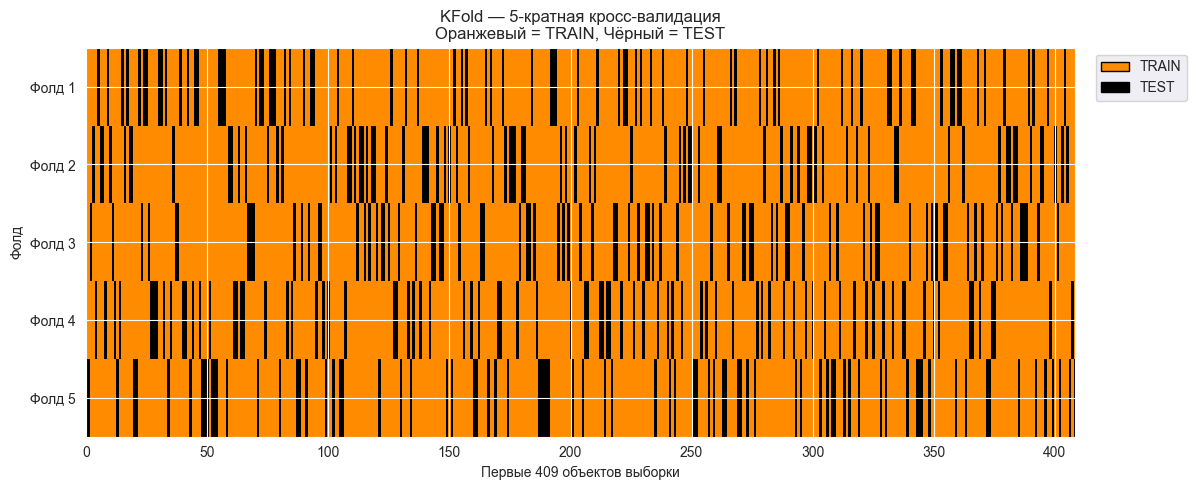

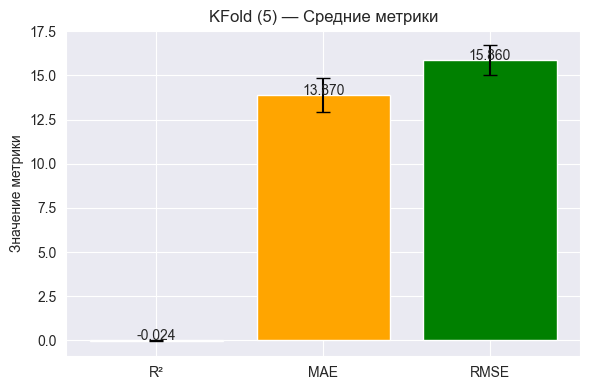


Сводная таблица метрик:


,Validation Type,R2,MAE,RMSE
0,ShuffleSplit (5 splits),-0.021685,14.054430,16.038701
1,KFold (5 splits),-0.023807,13.870165,15.859722


In [9]:
NFOLDS = 5
SEED = 42
splitter = KFold(n_splits=NFOLDS, shuffle=True, random_state=SEED)

scoring = {
    'r2': make_scorer(r2_score),
    'mae': make_scorer(mean_absolute_error, greater_is_better=False),
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred) ** 0.5, greater_is_better=False)
}

cv_res = cross_validate(
    clf, X, y,
    cv=splitter,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

res = {
    'cv': 'KFold (5 splits)',
    'r2_mean': np.mean(cv_res['test_r2']),
    'r2_std': np.std(cv_res['test_r2']),
    'mae_mean': -np.mean(cv_res['test_mae']),
    'mae_std': np.std(cv_res['test_mae']),
    'rmse_mean': -np.mean(cv_res['test_rmse']),
    'rmse_std': np.std(cv_res['test_rmse'])
}

print("Результаты KFold:")
print(f"R²   : {res['r2_mean']:.4f} ± {res['r2_std']:.4f}")
print(f"MAE  : {res['mae_mean']:.4f} ± {res['mae_std']:.4f}")
print(f"RMSE : {res['rmse_mean']:.4f} ± {res['rmse_std']:.4f}")

if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'R2', 'MAE', 'RMSE'])

new_row = pd.DataFrame([{
    'Validation Type': res['cv'],
    'R2': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}])

if 'stats' not in globals() or stats.empty:
    stats = new_row
else:
    stats = pd.concat([stats, new_row], ignore_index=True)

splits = list(splitter.split(X, y))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Первые {x_display} объектов выборки")
ax.set_ylabel('Фолд')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Фолд {i + 1}' for i in range(n_folds)])
ax.set_title('KFold — 5-кратная кросс-валидация\nОранжевый = TRAIN, Чёрный = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

metrics_plot = {
    'R²': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(),
              color=['skyblue', 'orange', 'green'],
              yerr=[res['r2_std'], res['mae_std'], res['rmse_std']],
              capsize=5)
ax.set_title('KFold (5) — Средние метрики')
ax.set_ylabel('Значение метрики')

for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.3f}", ha='center')

plt.tight_layout()
plt.show()

print("\nСводная таблица метрик:")
display(stats)

Валидация 3

GroupKFold


Результаты GroupKFold:
R²   : -0.0180 ± 0.0120
MAE  : 13.7702 ± 0.4948
RMSE : 15.8070 ± 0.3256


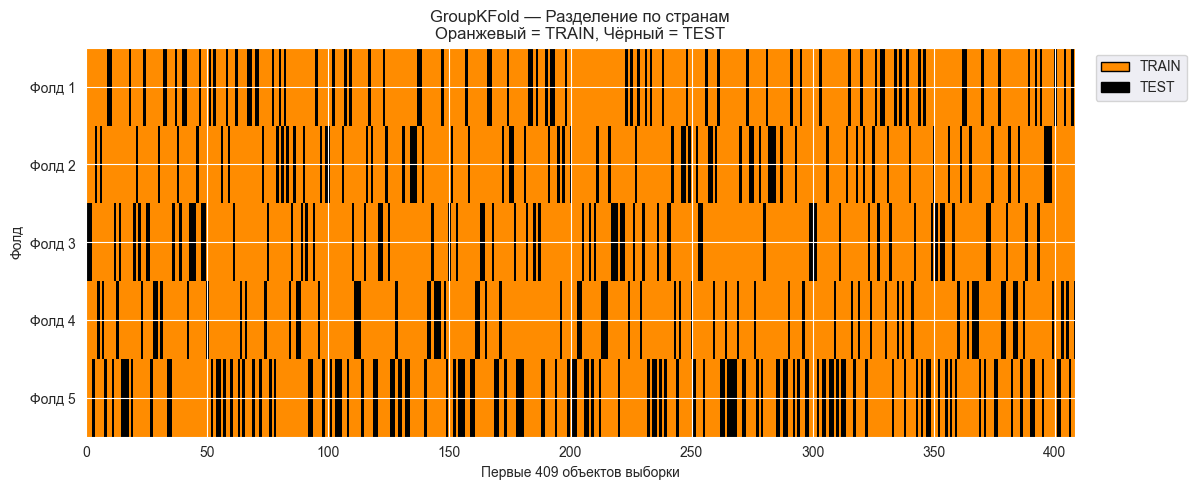

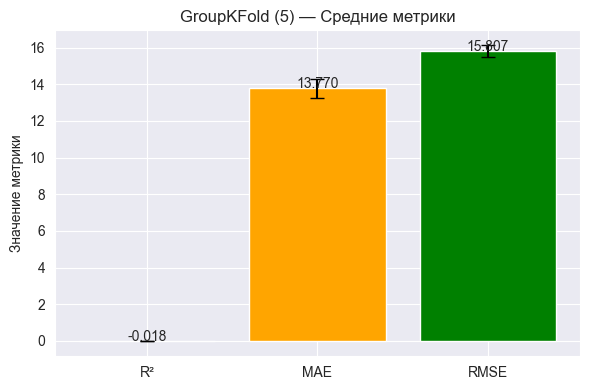


Сводная таблица метрик:


,Validation Type,R2,MAE,RMSE
0,ShuffleSplit (5 splits),-0.021685,14.054430,16.038701
1,KFold (5 splits),-0.023807,13.870165,15.859722
2,GroupKFold (5 splits),-0.018033,13.770226,15.806971


In [10]:
NFOLDS = 5
groups = train_df["Country"].to_numpy()  # группирующий признак (страна)
splitter = GroupKFold(n_splits=NFOLDS)

# === Метрики под регрессию ===
scoring = {
    'r2': make_scorer(r2_score),
    'mae': make_scorer(mean_absolute_error, greater_is_better=False),
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred) ** 0.5, greater_is_better=False)
}

# === Кросс-валидация ===
cv_res = cross_validate(
    clf, X, y,
    cv=splitter.split(X, y, groups=groups),
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

# === Усреднение метрик ===
res = {
    'cv': 'GroupKFold (5 splits)',
    'r2_mean': np.mean(cv_res['test_r2']),
    'r2_std': np.std(cv_res['test_r2']),
    'mae_mean': -np.mean(cv_res['test_mae']),
    'mae_std': np.std(cv_res['test_mae']),
    'rmse_mean': -np.mean(cv_res['test_rmse']),
    'rmse_std': np.std(cv_res['test_rmse'])
}

print("Результаты GroupKFold:")
print(f"R²   : {res['r2_mean']:.4f} ± {res['r2_std']:.4f}")
print(f"MAE  : {res['mae_mean']:.4f} ± {res['mae_std']:.4f}")
print(f"RMSE : {res['rmse_mean']:.4f} ± {res['rmse_std']:.4f}")

# === Добавляем в общую таблицу ===
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'R2', 'MAE', 'RMSE'])

stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': res['cv'],
        'R2': res['r2_mean'],
        'MAE': res['mae_mean'],
        'RMSE': res['rmse_mean']
    }])
], ignore_index=True)

# === Визуализация разбиений по группам ===
splits = list(splitter.split(X, y, groups=groups))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Первые {x_display} объектов выборки")
ax.set_ylabel('Фолд')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Фолд {i + 1}' for i in range(n_folds)])
ax.set_title('GroupKFold — Разделение по странам\nОранжевый = TRAIN, Чёрный = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === График метрик ===
metrics_plot = {
    'R²': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(),
              color=['skyblue', 'orange', 'green'],
              yerr=[res['r2_std'], res['mae_std'], res['rmse_std']],
              capsize=5)
ax.set_title('GroupKFold (5) — Средние метрики')
ax.set_ylabel('Значение метрики')

for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.3f}", ha='center')

plt.tight_layout()
plt.show()

print("\nСводная таблица метрик:")
display(stats)

Валидация 4


Результаты TimeSeriesSplit:
R²   : -0.0350 ± 0.0593
MAE  : 13.8184 ± 0.5190
RMSE : 15.8548 ± 0.6588


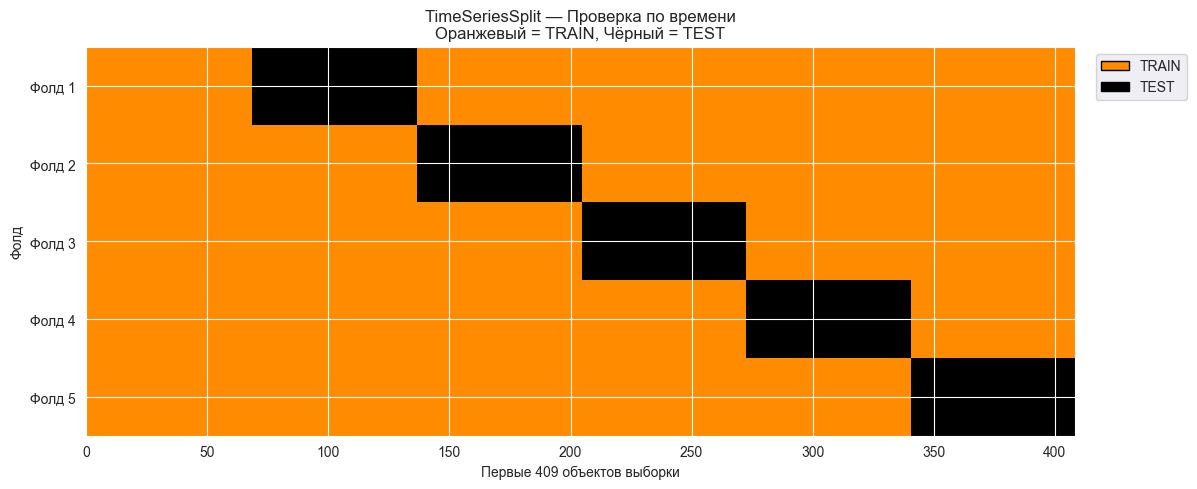

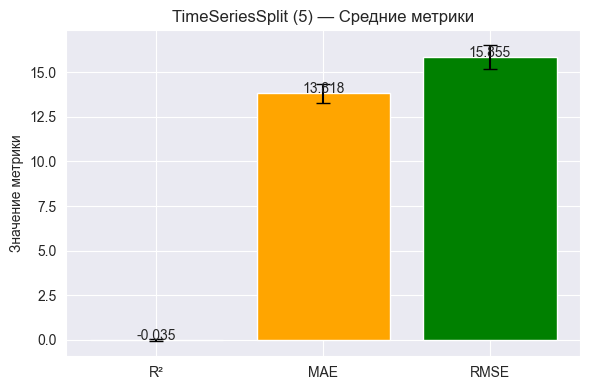


Сводная таблица метрик:


,Validation Type,R2,MAE,RMSE
0,ShuffleSplit (5 splits),-0.021685,14.054430,16.038701
1,KFold (5 splits),-0.023807,13.870165,15.859722
2,GroupKFold (5 splits),-0.018033,13.770226,15.806971
3,TimeSeriesSplit (5 splits),-0.035043,13.818358,15.854795


In [11]:
NFOLDS = 5
splitter = TimeSeriesSplit(n_splits=NFOLDS)

scoring = {
    'r2': make_scorer(r2_score),
    'mae': make_scorer(mean_absolute_error, greater_is_better=False),
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred) ** 0.5, greater_is_better=False)
}

cv_res = cross_validate(
    clf, X, y,
    cv=splitter,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)


res = {
    'cv': 'TimeSeriesSplit (5 splits)',
    'r2_mean': np.mean(cv_res['test_r2']),
    'r2_std': np.std(cv_res['test_r2']),
    'mae_mean': -np.mean(cv_res['test_mae']),
    'mae_std': np.std(cv_res['test_mae']),
    'rmse_mean': -np.mean(cv_res['test_rmse']),
    'rmse_std': np.std(cv_res['test_rmse'])
}

print("Результаты TimeSeriesSplit:")
print(f"R²   : {res['r2_mean']:.4f} ± {res['r2_std']:.4f}")
print(f"MAE  : {res['mae_mean']:.4f} ± {res['mae_std']:.4f}")
print(f"RMSE : {res['rmse_mean']:.4f} ± {res['rmse_std']:.4f}")

# === Обновляем или добавляем строку в stats ===
new_row = {
    'Validation Type': res['cv'],
    'R2': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

if 'stats' not in globals() or not isinstance(stats, pd.DataFrame):
    stats = pd.DataFrame(columns=['Validation Type', 'R2', 'MAE', 'RMSE'])

existing_index = stats.index[stats['Validation Type'] == res['cv']].tolist()
if existing_index:
    idx = existing_index[0]
    for key in ['R2', 'MAE', 'RMSE']:
        stats.loc[idx, key] = new_row[key]
else:
    stats = pd.concat([stats, pd.DataFrame([new_row])], ignore_index=True)

stats.drop_duplicates(subset=['Validation Type'], keep='last', inplace=True)



splits = list(splitter.split(X))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Первые {x_display} объектов выборки")
ax.set_ylabel('Фолд')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Фолд {i + 1}' for i in range(n_folds)])
ax.set_title('TimeSeriesSplit — Проверка по времени\nОранжевый = TRAIN, Чёрный = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

metrics_plot = {
    'R²': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(),
              color=['skyblue', 'orange', 'green'],
              yerr=[res['r2_std'], res['mae_std'], res['rmse_std']],
              capsize=5)
ax.set_title('TimeSeriesSplit (5) — Средние метрики')
ax.set_ylabel('Значение метрики')

for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.3f}", ha='center')

plt.tight_layout()
plt.show()

print("\nСводная таблица метрик:")
display(stats)

Валидация 5

Отдельные результаты (R²): [-0.07044086  0.02253031 -0.0319586  -0.05225349  0.01308991 -0.00609305
 -0.07347137 -0.03550114 -0.11391052 -0.03440093]
Отдельные результаты (MAE): [15.22743818 13.13981301 14.77774326 12.70972524 13.49610573 13.55406066
 13.23993126 12.03784634 14.8097159  16.13686076]
Отдельные результаты (RMSE): [17.10496642 15.50545435 16.49774924 14.64614648 15.54429494 15.66441313
 15.67583123 13.94359564 16.58312766 17.87952282]

Результаты RepeatedKFold:
R²   : -0.0382 ± 0.0395
MAE  : 13.9129 ± 1.2059
RMSE : 15.9045 ± 1.0946


/var/folders/nm/949gykw56q96mtx5h__xz9j80000gn/T/ipykernel_15474/750893733.py:65: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([


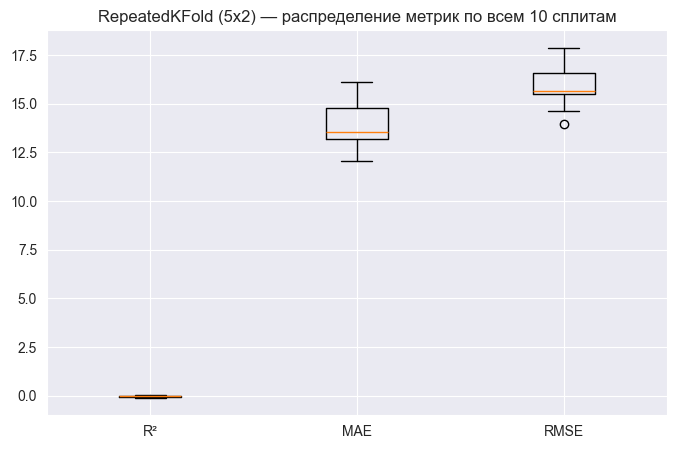


Сводная таблица метрик:


,Validation Type,R2,MAE,RMSE
0,ShuffleSplit (5 splits),-0.021685,14.054430,16.038701
1,KFold (5 splits),-0.023807,13.870165,15.859722
2,GroupKFold (5 splits),-0.018033,13.770226,15.806971
3,TimeSeriesSplit (5 splits),-0.035043,13.818358,15.854795
4,RepeatedKFold (5x2),-0.038241,13.912924,15.904510


In [12]:
from sklearn.model_selection import RepeatedKFold

NFOLDS = 5
NREPEATS = 2
SEED = 42
splitter = RepeatedKFold(n_splits=NFOLDS, n_repeats=NREPEATS, random_state=SEED)

scoring = {
    'r2': make_scorer(r2_score),
    'mae': make_scorer(mean_absolute_error, greater_is_better=False),
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred)**0.5, greater_is_better=False)
}

cv_res = cross_validate(
    clf, X, y,
    cv=splitter,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1
)

# === показываем распределение по всем 10 прогнам ===
print("Отдельные результаты (R²):", cv_res['test_r2'])
print("Отдельные результаты (MAE):", -cv_res['test_mae'])
print("Отдельные результаты (RMSE):", -cv_res['test_rmse'])

res = {
    'cv': 'RepeatedKFold (5x2)',
    'r2_mean': np.mean(cv_res['test_r2']),
    'r2_std': np.std(cv_res['test_r2']),
    'mae_mean': -np.mean(cv_res['test_mae']),
    'mae_std': np.std(cv_res['test_mae']),
    'rmse_mean': -np.mean(cv_res['test_rmse']),
    'rmse_std': np.std(cv_res['test_rmse'])
}

print("\nРезультаты RepeatedKFold:")
print(f"R²   : {res['r2_mean']:.4f} ± {res['r2_std']:.4f}")
print(f"MAE  : {res['mae_mean']:.4f} ± {res['mae_std']:.4f}")
print(f"RMSE : {res['rmse_mean']:.4f} ± {res['rmse_std']:.4f}")

# === добавляем в stats ===
new_row = {
    'Validation Type': res['cv'],
    'R2': res['r2_mean'],
    'MAE': res['mae_mean'],
    'RMSE': res['rmse_mean']
}

if 'stats' not in globals() or not isinstance(stats, pd.DataFrame):
    stats = pd.DataFrame(columns=['Validation Type', 'R2', 'MAE', 'RMSE'])

existing_index = stats.index[stats['Validation Type'] == res['cv']].tolist()
if existing_index:
    idx = existing_index[0]
    for key in ['R2', 'MAE', 'RMSE']:
        stats.loc[idx, key] = new_row[key]
else:
    stats = pd.concat([stats, pd.DataFrame([new_row])], ignore_index=True)

stats.drop_duplicates(subset=['Validation Type'], keep='last', inplace=True)

# === визуализация всех прогонов ===
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([
    cv_res['test_r2'],
    -cv_res['test_mae'],
    -cv_res['test_rmse']
], labels=['R²', 'MAE', 'RMSE'])
ax.set_title('RepeatedKFold (5x2) — распределение метрик по всем 10 сплитам')
ax.grid(True)
plt.show()

print("\nСводная таблица метрик:")
display(stats)